# External TMPHOTCAT dataset -- analysis of results

Data from `reference_dataset.json`.

## Configuration

In [ ]:
import json, os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

REF_JSON = 'reference/reference_dataset.json'   # <- files with predictions
EPS      = 1e-5           # eps for f transformation
E_WINDOW = (0.0, 8.0)     # window for regression task (eV)
VIS      = (350.0, 650.0) # window for binary task (nm)
F_THRESH = 0.01           # threshold for oscillator strength (binary)
EXPT_POS_FRAC = 0.38      # relative intensity threshold applied to the experimental spectrum
CLASSES  = ['3d', '345']
COL      = {'3d':'#4a72b0', '345':'#c0603a'}

EXCLUDE = {'Ir_CNC_6'} # one bimetallic Ir complex excluded; the Cu/Fe ferrocenyl complexes are retained and analysed separately
data = json.load(open(REF_JSON))
n0 = len(data)
data = {k: v for k, v in data.items()
        if v.get('stem') not in EXCLUDE and v.get('base_id') not in EXCLUDE}

seeds = sorted({s for v in data.values() if v['predictions']
                for cls in v['predictions'].values() for s in cls})
print('files:', len(data), '| seeds:', seeds)

files: 131 | seeds: ['1234', '2137', '42']


In [2]:
mpl.rcParams.update({
    'font.family'     : 'DejaVu Sans',   
    'font.size'       : 11,
    'axes.titlesize'  : 12,
    'axes.labelsize'  : 12,
    'xtick.labelsize' : 10,
    'ytick.labelsize' : 10,
    'legend.fontsize' : 9,
    'figure.titlesize': 14,
})

## TD-DFT threshold vs experimental

In [13]:
def pred_binary(pr, cls):
    if cls not in pr: return None
    ps = [r['binary']['proba'] for r in pr[cls].values() if 'binary' in r]
    return int(np.mean(ps) > 0.5) if ps else None

def truth_tddft(td):
    if not td: return None
    w = np.array(td['wavelength_nm']); f = np.array(td['f'])
    return int(np.any((w >= VIS[0]) & (w <= VIS[1]) & (f >= F_THRESH)))

def truth_expt(ex, alpha=EXPT_POS_FRAC):
    if not ex: return None
    w = np.array(ex['wavelength_nm']); it = np.array(ex['intensity'])
    if it.max() <= 0: return None
    m = (w >= VIS[0]) & (w <= VIS[1])
    return int(m.any() and it[m].max() >= alpha * it.max())

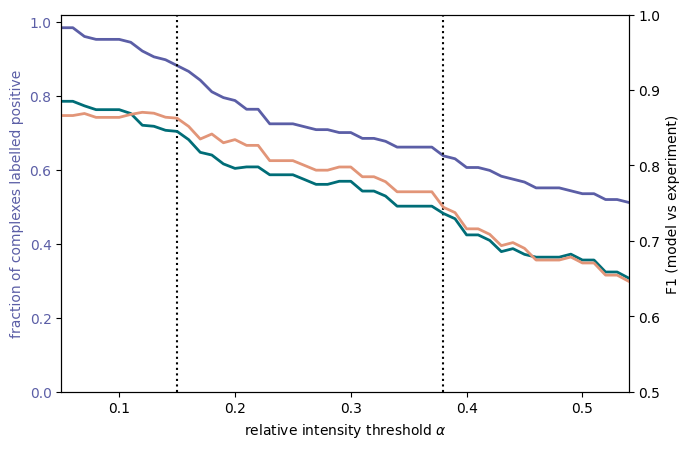

In [16]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import f1_score

COL   = {'3d':'#006d77', '345':'#e29578'}
LABEL = {'3d':'3d-trained', '345':'345-trained'}
RATE_COL = '#5b5ea6'
alphas = np.arange(0.05, 0.55, 0.01)

exps = [(fn, v) for fn, v in data.items() if v['experiment']]
td_rate = np.mean([truth_tddft(v['tddft']) for _, v in exps if v['tddft'] is not None])
pred_cache = {cls: {fn: pred_binary(v['predictions'] or {}, cls) for fn, v in data.items()}
              for cls in CLASSES}

rates = []
f1 = {cls: [] for cls in CLASSES}
for a in alphas:
    yt_all = {fn: truth_expt(v['experiment'], alpha=a) for fn, v in data.items() if v['experiment']}
    valid = {fn: t for fn, t in yt_all.items() if t is not None}
    rates.append(np.mean(list(valid.values())))
    for cls in CLASSES:
        yt = [valid[fn] for fn in valid if pred_cache[cls][fn] is not None]
        yp = [pred_cache[cls][fn] for fn in valid if pred_cache[cls][fn] is not None]
        f1[cls].append(f1_score(yt, yp, pos_label=1, zero_division=0) if yt else np.nan)
rates = np.array(rates)
cross = np.interp(0, (rates - td_rate)[::-1], alphas[::-1]) if (rates.min() < td_rate < rates.max()) else np.nan

fig, ax1 = plt.subplots(figsize=(7, 4.6))
ax2 = ax1.twinx()

l1, = ax1.plot(alphas, rates, '-', color=RATE_COL, lw=2, label='experimental positive rate')
ax1.set_ylabel('fraction of complexes labelled positive', color=RATE_COL)
ax1.tick_params(axis='y', labelcolor=RATE_COL)
ax1.set_ylim(0, 1.02)

fl = []
for cls in CLASSES:
    li, = ax2.plot(alphas, f1[cls], '-', color=COL[cls], lw=2, label=f'F1 {LABEL[cls]}')
    fl.append(li)
ax2.set_ylabel('F1 (model vs experiment)')
ax2.set_ylim(0.5, 1.0)

# vertical lines
v1 = ax1.axvline(0.15, ls=':', color='k', lw=1.5, label=r'adopted $\alpha=0.15$')
v1 = ax1.axvline(0.38, ls=':', color='k', lw=1.5, label=r'adopted $\alpha=0.15$')

if np.isfinite(cross):
    ax1.axvline(cross, ls=':', color='0.5', lw=1.2)

ax1.set_xlabel(r'relative intensity threshold $\alpha$')
ax1.set_xlim(alphas.min(), alphas.max())

plt.tight_layout(); plt.savefig('alpha_combined.eps', bbox_inches='tight'); plt.show()

### Examples of TMCs with defined alpha (experiment)

picked (ratio | @0.15 | @0.38):
  Cu50_XantPhos-quintri: 0.37 | positive | negative
  Cu50_dppf-pytri: 0.29 | positive | negative
  Ru-CN_1: 0.20 | positive | negative
  Ir-he_4: 0.11 | negative | negative


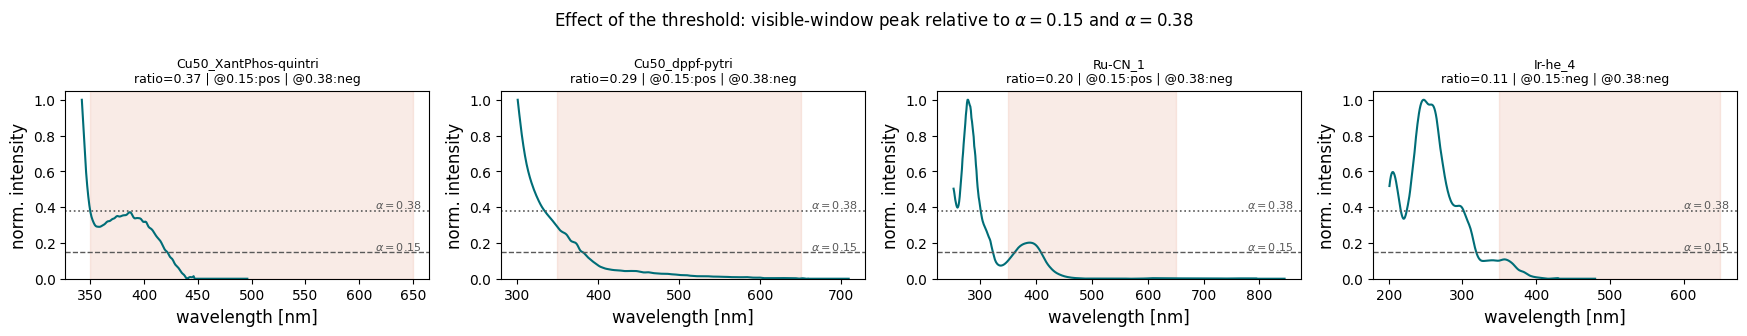

In [5]:
import numpy as np, matplotlib.pyplot as plt

A_LOW, A_HIGH = 0.15, 0.38          # adopted vs matched-to-TDDFT
VISLO, VISHI = VIS

def vis_ratio(ex):
    w = np.array(ex['wavelength_nm']); it = np.array(ex['intensity'])
    if it.max() <= 0: return None
    m = (w >= VISLO) & (w <= VISHI)
    return it[m].max()/it.max() if m.any() else None

ratios = {fn: vis_ratio(v['experiment']) for fn, v in data.items() if v['experiment']}
ratios = {fn: r for fn, r in ratios.items() if r is not None}

targets = [0.37, 0.28, 0.20, 0.10]   
picked, used = [], set()
for t in targets:
    fn = min((f for f in ratios if f not in used), key=lambda f: abs(ratios[f]-t))
    picked.append(fn); used.add(fn)

def cls_at(r, a): return 'positive' if r >= a else 'negative'

print('picked (ratio | @0.15 | @0.38):')
for fn in picked:
    r = ratios[fn]
    print(f'  {data[fn]["stem"]}: {r:.2f} | {cls_at(r,A_LOW)} | {cls_at(r,A_HIGH)}')

n = len(picked); fig, axes = plt.subplots(1, n, figsize=(4.4*n, 3.4), squeeze=False); axes = axes.ravel()
for ax, fn in zip(axes, picked):
    ex = data[fn]['experiment']; r = ratios[fn]
    w = np.array(ex['wavelength_nm']); it = np.array(ex['intensity'])
    o = np.argsort(w); w, it = w[o], it[o]; itn = it/it.max()
    ax.plot(w, itn, color='#006d77', lw=1.5)
    ax.axvspan(VISLO, VISHI, color='#e29578', alpha=0.18)
    ax.axhline(A_LOW,  ls='--', color='0.35', lw=1)
    ax.axhline(A_HIGH, ls=':',  color='0.35', lw=1.2)
    ax.text(0.98, A_LOW,  r'$\alpha=0.15$', transform=ax.get_yaxis_transform(),
            ha='right', va='bottom', fontsize=8, color='0.35')
    ax.text(0.98, A_HIGH, r'$\alpha=0.38$', transform=ax.get_yaxis_transform(),
            ha='right', va='bottom', fontsize=8, color='0.35')
    ax.set_title(f'{data[fn]["stem"]}\nratio={r:.2f} | @0.15:{cls_at(r,A_LOW)[:3]} | @0.38:{cls_at(r,A_HIGH)[:3]}',
                 fontsize=9)
    ax.set_xlabel('wavelength [nm]'); ax.set_ylabel('norm. intensity'); ax.set_ylim(0, 1.05)
plt.suptitle('Effect of the threshold: visible-window peak relative to $\\alpha=0.15$ and $\\alpha=0.38$', fontsize=12)
plt.tight_layout()
#plt.savefig('SI_threshold_regimes.eps', bbox_inches='tight')
plt.show()

### Confusion matrices

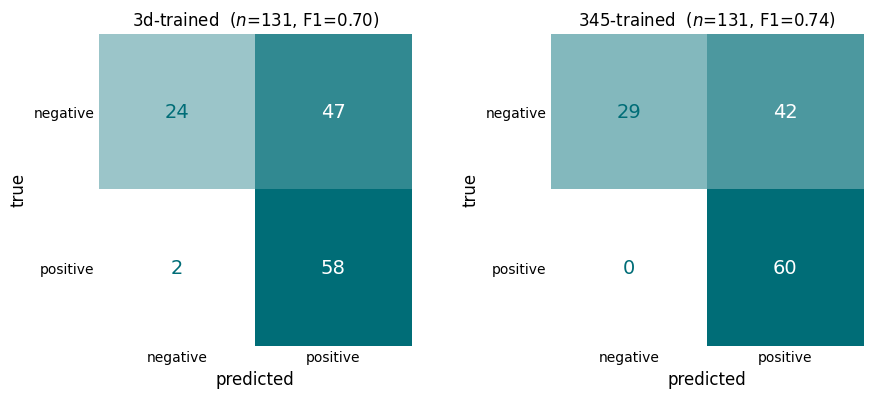

In [6]:
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from matplotlib.colors import LinearSegmentedColormap

TEAL_SEQ = LinearSegmentedColormap.from_list('teal_seq', ['#ffffff', '#006d77'])

def cm_figure(ref_fn, title, fname=None):
    fig, ax = plt.subplots(1, len(CLASSES), figsize=(4.6*len(CLASSES), 4.4), squeeze=False)
    ax = ax[0]
    for a, cls in zip(ax, CLASSES):
        yt, yp = [], []
        for v in data.values():
            t = ref_fn(v); p = pred_binary(v['predictions'] or {}, cls)
            if t is not None and p is not None:
                yt.append(t); yp.append(p)
        cm = confusion_matrix(yt, yp, labels=[0, 1])
        disp = ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive'])
        disp.plot(ax=a, colorbar=False, cmap=TEAL_SEQ, values_format='d',
                  text_kw={'fontsize': 14})
        f1 = f1_score(yt, yp, pos_label=1, zero_division=0) if yt else float('nan')
        a.set_title(f'{cls}-trained  ($n$={len(yt)}, F1={f1:.2f})')
        a.set_xlabel('predicted'); a.set_ylabel('true')
        a.tick_params(length=0)
        for spine in a.spines.values():
            spine.set_visible(False)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    if fname:
        plt.savefig(fname, bbox_inches='tight')
    plt.show()
cm_figure(lambda v: truth_tddft(v['tddft']), '', fname='confusion_matrix_tddft.eps')

## Regression metrics

### Configuration

In [ ]:
def ens_seed(pr_cls, key, seed):
    r = pr_cls.get(seed)
    return np.array(r[key]) if (r and key in r and len(r[key])) else None

def build_pairs_seed():
    rows=[]
    for fn,v in data.items():
        td=v['tddft']; pr=v['predictions']
        if not td or not pr: continue
        ev_ref=np.array(td['energy_eV']); f_ref=np.array(td['f'])
        for cls in CLASSES:
            if cls not in pr: continue
            for seed in pr[cls]:
                e=ens_seed(pr[cls],'energy_eV',seed); lf=ens_seed(pr[cls],'log10f',seed)
                if e is None: continue
                n=min(len(ev_ref),len(e),10)
                for i in range(n):
                    rows.append(dict(file=fn, block=v['block'], charge=v['charge'],
                        n_atoms=v['n_atoms'], metal=v['metal'], cls=cls, seed=seed, state=i,
                        ev_ref=ev_ref[i], ev_pred=e[i], lf_ref=np.log10(np.maximum(f_ref[i], EPS)) ,
                        lf_pred=(lf[i] if lf is not None and i<len(lf) else np.nan)))
    out = pd.DataFrame(rows)
    out['ok'] = (out.ev_pred >= E_WINDOW[0]) & (out.ev_pred <= E_WINDOW[1])
    return out

def stat(sub, tgt, which):
    if tgt=='E':
        g=sub[sub.ok]; rc,pc='ev_ref','ev_pred'
    else:
        g=sub; rc,pc='lf_ref','lf_pred'
    return (r2(g[rc],g[pc]) if which=='R2' else mae(g[rc],g[pc]))

def stat_ms(sub, tgt, which):
    """mean +/- std of the metric computed separately for each seed."""
    vals=[stat(sub[sub.seed==s], tgt, which) for s in sub.seed.unique()]
    vals=[x for x in vals if np.isfinite(x)]
    return (np.mean(vals), np.std(vals)) if vals else (np.nan, np.nan)

def r2(y,yh):
    y,yh=np.asarray(y,float),np.asarray(yh,float); m=np.isfinite(y)&np.isfinite(yh)
    y,yh=y[m],yh[m]
    if len(y)<2: return np.nan
    ss=np.sum((y-y.mean())**2); return 1-np.sum((y-yh)**2)/ss if ss>0 else np.nan

def mae(y,yh):
    y,yh=np.asarray(y,float),np.asarray(yh,float); m=np.isfinite(y)&np.isfinite(yh)
    return float(np.mean(np.abs(y[m]-yh[m]))) if m.sum() else np.nan

def grouped_panels(cats, subfn, suptitle, xlabel='', fname=None, val_rotation=0,
                   fmt_mae='.3f', fmt_r2='.2f', show_values=True, show_errbars=True,
                   show_logf=True, figsize=(20, 9)):
    energy_color, osc_color = '#006d77', '#e29578'
    col = {CLASSES[0]: energy_color, CLASSES[1]: osc_color}

    panels = [
        [('E',    'MAE', 'MAE [eV]', 'Excitation energy MAE',  '↓'),
         ('E',    'R2',  'R²',       'Excitation energy R²',   '↑')],
        [('logf', 'MAE', 'MAE',      'log₁₀(max(ε, f)) MAE',   '↓'),
         ('logf', 'R2',  'R²',       'log₁₀(max(ε, f)) R²',    '↑')],
    ]
    if not show_logf:
        panels = panels[:1]                        
    nrows = len(panels)
    fig, ax = plt.subplots(nrows, 2, figsize=figsize, squeeze=False)

    x = np.arange(len(cats)); w = 0.38
    ns = [pd.concat([subfn(cls, c) for cls in CLASSES]).file.nunique() for c in cats]

    for r in range(nrows):
        for cc in range(2):
            a = ax[r][cc]
            tgt, which, ylab, tt, arrow = panels[r][cc]
            fmt = fmt_mae if which == 'MAE' else fmt_r2
            ymin, ymax = (0, 1.2) if which == 'MAE' else (-0.2, 1.1)

            for k, cls in enumerate(CLASSES):
                ms   = [stat_ms(subfn(cls, c), tgt, which) for c in cats]
                vals = [m for m, _ in ms]
                errs = [s if np.isfinite(s) else 0.0 for _, s in ms]   
                xs = x + (k - 0.5) * w
                a.bar(xs, vals, w,
                      yerr=(errs if show_errbars else None), capsize=(3 if show_errbars else 0),
                      color=col[cls], label=f'{cls}-trained', error_kw=dict(lw=0.8))
                if not show_values:
                    continue
                for xi, v, e in zip(xs, vals, errs):
                    if v is None or not np.isfinite(v):
                        continue
                    ecap = e if show_errbars else 0.0
                    if v < ymin:
                        a.annotate(f'{format(v, fmt)} ↓', (xi, 0), textcoords='offset points',
                                   xytext=(0, 3), ha='center', va='bottom', fontsize=9, color='k',
                                   rotation=val_rotation, rotation_mode='anchor')
                    elif v > ymax:
                        a.annotate(f'{format(v, fmt)} ↑', (xi, 0), textcoords='offset points',
                                   xytext=(0, 3), ha='center', va='bottom', fontsize=9, color='k',
                                   rotation=val_rotation, rotation_mode='anchor')
                    elif v < 0:
                        a.annotate(format(v, fmt), (xi, 0), textcoords='offset points',
                                   xytext=(0, 3), ha='center', va='bottom', fontsize=9,
                                   rotation=val_rotation, rotation_mode='anchor')
                    else:
                        a.annotate(format(v, fmt), (xi, min(v + ecap, ymax)), textcoords='offset points',
                                   xytext=(0, 3), ha='center', va='bottom', fontsize=9,
                                   rotation=val_rotation, rotation_mode='anchor')

            a.set_xticks(x); a.set_xticklabels([str(c) for c in cats])
            a.set_ylabel(ylab); a.set_title(f'{tt}  {arrow}', fontsize=12)
            a.axhline(0, color='k', lw=0.6); a.set_xlabel(xlabel); a.set_ylim(ymin, ymax)
            a.tick_params(axis='both', labelsize=11)

    plt.suptitle(suptitle, fontsize=13); plt.tight_layout(rect=[0, 0, 1, 0.94])
    if fname:
        plt.savefig(fname, dpi=400, bbox_inches='tight')
    plt.show()
    return dict(zip([str(c) for c in cats], ns))

### Figures

#### Frequency analysis

Sum: 131


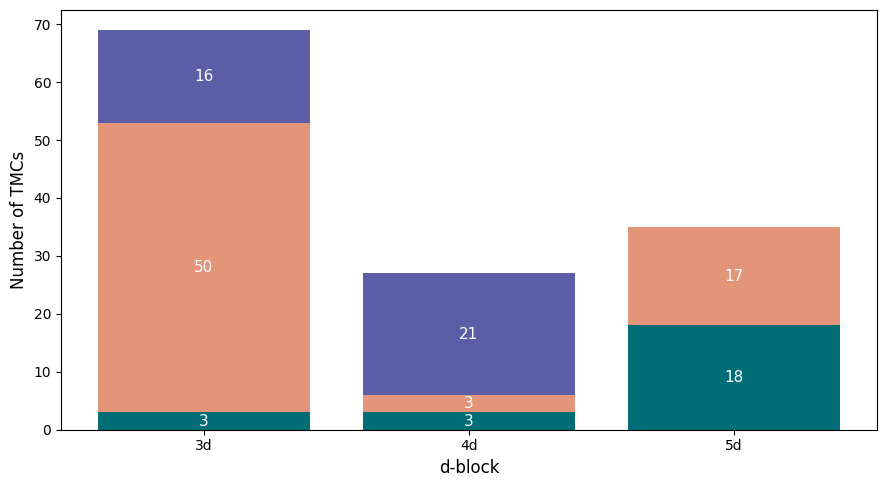

In [8]:
BLOCKS  = ['3d', '4d', '5d']
CHARGES = [0, 1, 2]
CH_COL  = {0: '#006d77', 1: '#e29578', 2: '#5b5ea6'}   # teal / salmon / indigo
CH_LAB  = {0: 'neutral (0)', 1: 'cation (+1)', 2: 'dication (+2)'}

counts = {b: {q: 0 for q in CHARGES} for b in BLOCKS}
skipped = []
for v in data.values():
    b, q = v.get('block'), v.get('charge')
    if b in counts and q in CHARGES:
        counts[b][q] += 1
    else:
        skipped.append((b, q))
if skipped:
    print('Skipped:', skipped)
print('Sum:', sum(counts[b][q] for b in BLOCKS for q in CHARGES))

import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(BLOCKS))
fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(BLOCKS))
for q in CHARGES:
    vals = np.array([counts[b][q] for b in BLOCKS])
    ax.bar(x, vals, bottom=bottom, color=CH_COL[q], width=0.8, label=CH_LAB[q])
    for xi, (val, bot) in enumerate(zip(vals, bottom)):
        if val > 0:
            ax.text(xi, bot + val/2, str(val), ha='center', va='center',
                    color='white', fontsize=11)
    bottom += vals

ax.set_xticks(x); ax.set_xticklabels(BLOCKS)
ax.set_xlabel('d-block'); ax.set_ylabel('Number of TMCs')
ax.set_ylim(0, bottom.max() * 1.05)
plt.tight_layout()
#plt.savefig('tmc_count_by_block.eps', bbox_inches='tight')
plt.show()

#### Predictions errors

`grouped_panels()` has been prepared in a flexible way, so that a single function can be used to plot different kinds of prediction-error figures.

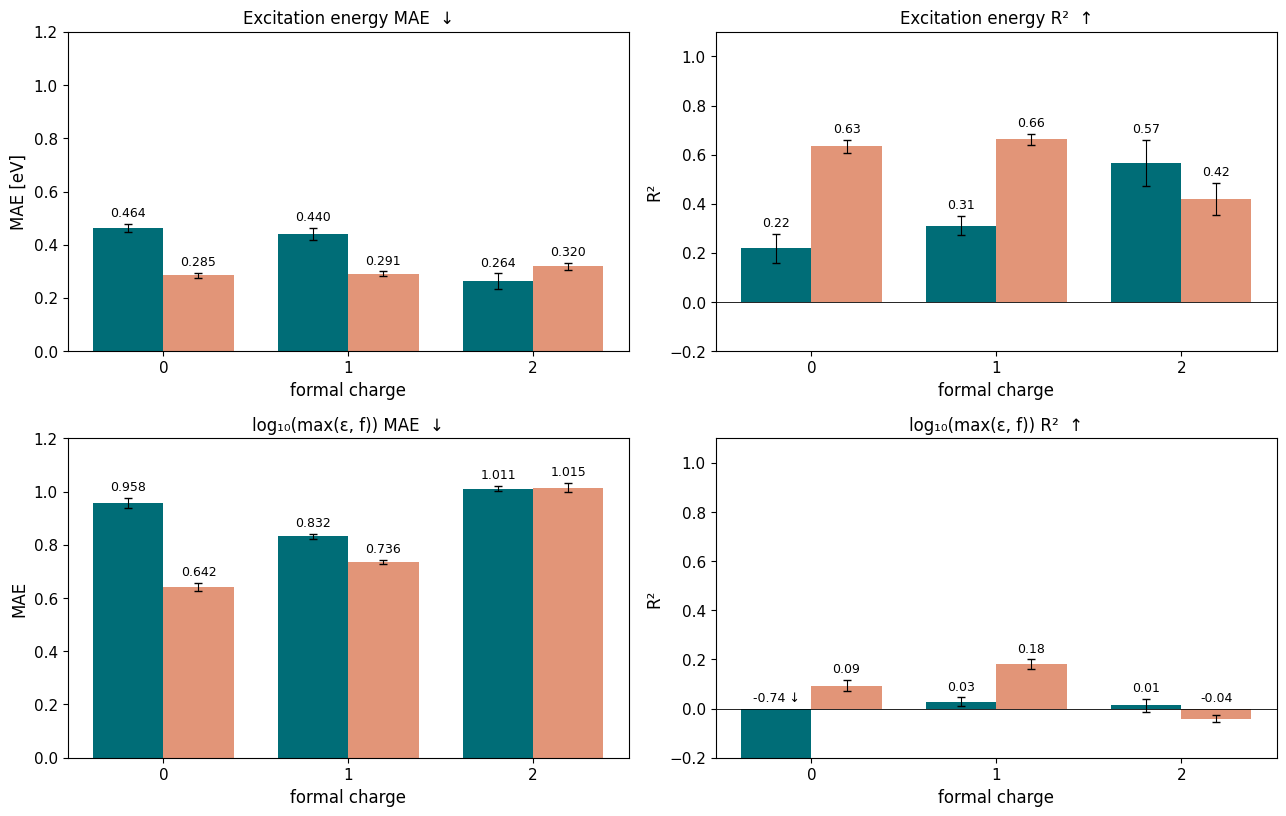

{'0': 24, '1': 70, '2': 37}

In [9]:
df = build_pairs_seed()

# --- AGGREGATED ---
#grouped_panels(['all'], lambda cls,c: df[df.cls==cls], '', '')

# --- BY BLOCKS ---
#grouped_panels(['3d','4d','5d'], lambda cls,b: df[(df.cls==cls)&(df.block==b)], '', 'd-block', fname='by_block_tmphoto_with_f.eps', show_errbars=True, show_logf=True, figsize=(13,9)) #figsize (13,9)

# --- BY BLOCKS x SIZE ---
#df['bs'] = df.block + '/' + df['size']
#keys = [f'{b}/{s}' for b in ['3d','4d','5d'] for s in ['<85','>=85']]
#grouped_panels(keys,
#    lambda cls,k: df[(df.cls==cls)&(df['bs']==k)], 'block × size', 'BY d-BLOCK × SIZE — pred vs TD-DFT')

# --- BY CHARGE ---
grouped_panels([0, 1, 2], lambda cls, q: df[(df.cls==cls)&(df.charge==q)], '', 'formal charge', fname='by_charge_tmphoto_with_f.eps', show_values=True, show_errbars=True, figsize=(13,9), show_logf=True)  # figsize (13,9)

# --- BY BLOCK x CHARGE ---
#combos=[f'{b}/q{q}' for b in ['3d','4d','5d'] for q in [0,1,2]
#        if df[(df.block==b)&(df.charge==int(q if isinstance(q,int) else q))].file.nunique()>=3]
#def sel(cls, key):
#    b, q = key.split('/q')
#    return df[(df.cls==cls) & (df.block==b) & (df.charge==int(q))]

#grouped_panels(combos, sel, '', xlabel='block × charge', val_rotation=-0, fmt_mae='.2f', fmt_r2='.2f', fname='blockxcharge.eps', show_values=True, show_errbars=True, figsize=(22,9), show_logf=True) #figsize (20,9)


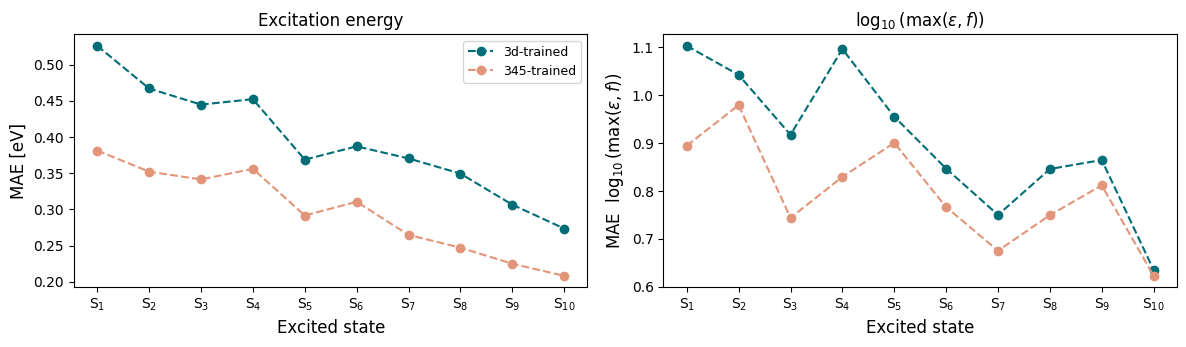

In [10]:
ALLB = ['3d', '4d', '5d']
LABEL = {'3d': '3d-trained', '345': '345-trained'}

def mae_state(ax, tgt, blocks, title):
    for cls in CLASSES:
        if tgt == 'E':
            g = df[df.ok & (df.cls == cls) & (df.block.isin(blocks))]
            err = (g.ev_pred - g.ev_ref).abs()
        else:
            g = df[(df.cls == cls) & (df.block.isin(blocks))]
            err = (g.lf_pred - g.lf_ref).abs()
        m = err.groupby(g.state).mean()
        ax.plot(m.index, m.values, 'o--', color=COL[cls], label=LABEL[cls])
    ax.set_xticks(range(10)); ax.set_xticklabels([f'S$_{{{i+1}}}$' for i in range(10)])
    ax.set_xlabel('Excited state')
    ax.set_ylabel('MAE [eV]' if tgt == 'E' else r'MAE  $\log_{10}(\max(\varepsilon,f))$')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), squeeze=False)
mae_state(axes[0][0], 'E',    ALLB, 'Excitation energy')
mae_state(axes[0][1], 'logf', ALLB, r'$\log_{10}(\max(\varepsilon, f))$')
axes[0][0].legend()
plt.tight_layout()
#plt.savefig('mae_per_state_all.eps', bbox_inches='tight')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


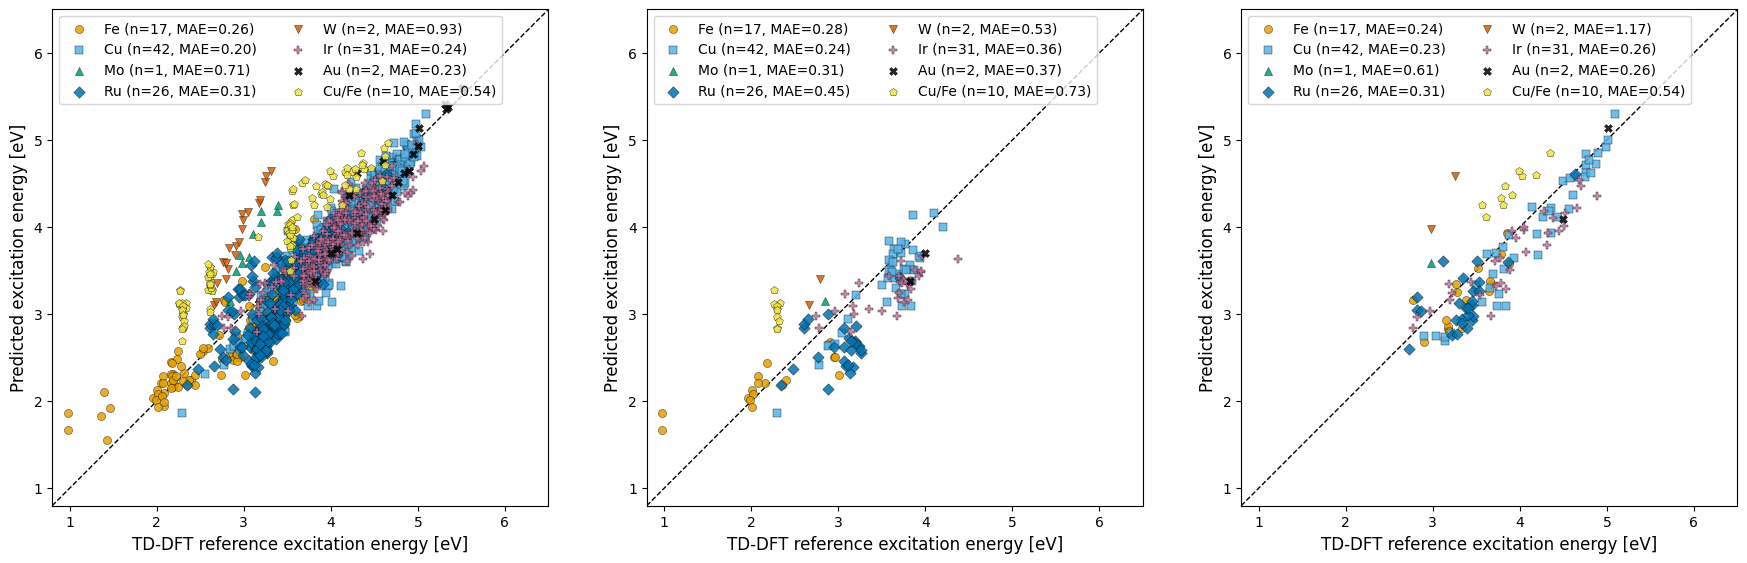

In [11]:
import re
from matplotlib.colors import LinearSegmentedColormap

lo, hi = 0.8, 6.5
TEAL, SALMON = '#006d77', '#e29578'

Zm = {'Fe':26,'Cu':29,'Mo':42,'Ru':44,'W':74,'Ir':77,'Au':79}
METALS_Z  = sorted(Zm, key=Zm.get)
METAL_COL = dict(zip(METALS_Z,
              ['#E69F00','#56B4E9','#009E73','#0072B2','#D55E00','#CC79A7','#000000']))
METAL_MRK = {'Fe':'o','Cu':'s','Mo':'^','Ru':'D','W':'v','Ir':'P','Au':'X'}

METAL_COL['CuFe'] = '#F0E442'      
METAL_MRK['CuFe'] = 'p'
PLOT_ORDER = METALS_Z + ['CuFe']  
DISPLAY = {'CuFe': 'Cu/Fe'}
METAL_SORT = 'Z'

_METAL_SYMS = {'Sc','Ti','V','Cr','Mn','Fe','Co','Ni','Cu','Zn',
               'Y','Zr','Nb','Mo','Tc','Ru','Rh','Pd','Ag','Cd',
               'La','Hf','Ta','W','Re','Os','Ir','Pt','Au','Hg'}
def _metal_label(fname, fallback):
    if 'dppf' in str(fname).lower():           # ferrocene -> separate Cu/Fe category
        return 'CuFe'
    m = re.match(r'([A-Z][a-z]?)', str(fname))
    return m.group(1) if (m and m.group(1) in _METAL_SYMS) else fallback

def _mae(s): return (s.ev_pred - s.ev_ref).abs().mean()

def base_ax(ax, title):
    ax.plot([lo,hi],[lo,hi],'k--',lw=1)
    ax.set_xlim(lo,hi); ax.set_ylim(lo,hi); ax.set_aspect('equal')
    ax.set_xlabel('TD-DFT reference excitation energy [eV]'); ax.set_ylabel('Predicted excitation energy [eV]')
    ax.set_title(title)

def draw_metal(ax, sub):
    present = [m for m in PLOT_ORDER if m in sub.metal.unique()]
    if METAL_SORT == 'mae':
        present = sorted(present, key=lambda m: _mae(sub[sub.metal==m]))
    for m in present:
        s = sub[sub.metal==m]
        if len(s)==0: continue
        ax.scatter(s.ev_ref, s.ev_pred, color=METAL_COL[m], marker=METAL_MRK[m],
                   s=34, alpha= 0.85,
                   edgecolor= 'black', linewidth= 0.3,
                   zorder= 3,
                   label=f'{DISPLAY.get(m, m)} (n={s.file.nunique()}, MAE={_mae(s):.2f})')
    ax.legend(fontsize=10, loc='upper left', ncol=2)

# ENSEMBLE
gsrc = df[df.ok & (df.cls=='345')].copy()
gsrc['metal'] = [_metal_label(f, m) for f, m in zip(gsrc.file, gsrc.metal)]   # <- metal relabelling, incl. the Cu/Fe category
agg = (gsrc.groupby(['file','block','charge','metal','state'], as_index=False)
          .agg(ev_ref=('ev_ref','mean'), ev_pred=('ev_pred','mean'), lf_ref=('lf_ref','mean')))

g_all  = agg
g_s1   = agg[agg.state == 0]
g_maxf = agg.loc[agg.groupby('file').lf_ref.idxmax()]

panels = [('', g_all), ('', g_s1), ('', g_maxf)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (title, sub) in zip(axes, panels):
    draw_metal(ax, sub)
    base_ax(ax, title)
plt.tight_layout()
plt.savefig('scatter_states_by_metal.eps', bbox_inches='tight')
plt.show()

## Solvent effect

In [12]:
solvent_df = pd.read_excel('TMPHOTCAT-137_notes.xlsx')
df = build_pairs_seed()

df['stem'] = df.file.map({fn: v['stem'] for fn, v in data.items()})

# merge: ID->stem, Solvent->solvent 

df = df.merge(
    solvent_df[['ID', 'Solvent']].rename(columns={'ID': 'stem', 'Solvent': 'solvent'}),
    how='left', on='stem'
)

df['ev_error'] = np.abs(df['ev_pred'] - df['ev_ref'])

In [13]:
print(df['solvent'].value_counts().sum()/60)
df['solvent'].value_counts() # every TMC have been predicted 60 times (3 seeds, 10 energies, 2 types of models)

118.0


solvent
MeCN      3540
CH2Cl2    2760
THF        360
DMF        240
MePh       180
Name: count, dtype: int64

In [ ]:
FIX = {
    'Cu50_DPEPhos-dmbp':  'CH2Cl2',
    'Cu50_DPEPhos-dtbbp': 'CH2Cl2',
    'Ir_isoCN_3_trans-N': 'MeCN',
    'Ir_isoCN_6_trans-N': 'MeCN',
    'Ir_isoCN_7_trans-N': 'MeCN',
    'Ir_isoCN-acac_2_trans-N': 'MePh',
    'Ir_isoCN-acac_3_trans-N': 'MePh',
    'Cu-xant-dmp': 'CH2Cl2',
    'Cu50_DPEPhos-quintri_b': 'CH2Cl2'
}

istn = {s.strip().lower(): s for s in df['solvent'].dropna().astype(str).unique()}

for stem, solv in FIX.items():
    val = istn.get(solv.strip().lower(), solv)
    if solv.strip().lower() not in istn:
        print(f"  WARNING: '{solv}' not in existing solvents'")
    m = df['file'].astype(str).str.startswith(stem + '_') & df['solvent'].isna()
    print(f"  {stem:<24} -> {val:<10} {m.sum():>4} rows")
    df.loc[m, 'solvent'] = val

print(df.loc[df['solvent'].isna(), 'file'].unique())

print(df.groupby('solvent')['file'].nunique().sort_values(ascending=False).to_string())
print('Sum:', df.loc[df['solvent'].notna(), 'file'].nunique())

  Cu50_DPEPhos-dmbp        -> CH2Cl2       60 rows
  Cu50_DPEPhos-dtbbp       -> CH2Cl2       60 rows
  Ir_isoCN_3_trans-N       -> MeCN         60 rows
  Ir_isoCN_6_trans-N       -> MeCN         60 rows
  Ir_isoCN_7_trans-N       -> MeCN         60 rows
  Ir_isoCN-acac_2_trans-N  -> MePh         60 rows
  Ir_isoCN-acac_3_trans-N  -> MePh         60 rows
  Cu-xant-dmp              -> CH2Cl2       60 rows
  Cu50_DPEPhos-quintri_b   -> CH2Cl2       60 rows
<ArrowStringArray>
['Cu50_XantPhos-quintri_b_PBE-D3_def2SVP_coords_11.xyz',
                  'Ir-ppy_PBE-D3_def2SVP_coords_01.xyz',
                 'Ru-phen_PBE-D3_def2SVP_coords_21.xyz',
                 'Ru-qd_4_PBE-D3_def2SVP_coords_21.xyz']
Length: 4, dtype: str
solvent
MeCN      62
CH2Cl2    50
THF        6
MePh       5
DMF        4
suma: 127


In [15]:
import numpy as np

EPS_SOLV = {
    'MeCN':    37.5,   
    'DMF':     36.7,   
    'CH2Cl2':   8.9,   
    'THF':      7.5,   
    'MePh':     2.4,   
}
df['eps'] = df.solvent.map(EPS_SOLV)

sub = df[df.ok & (df.cls == '345')].copy()      # only 345 model
sub['resid'] = sub.ev_pred - sub.ev_ref          

g = (sub.groupby(['charge', 'solvent'])
        .agg(eps=('eps', 'first'),
             n_cplx=('file', 'nunique'),
             n_states=('resid', 'size'),
             mean_resid=('resid', 'mean'),      
             mae=('resid', lambda s: s.abs().mean()))
        .reset_index()
        .sort_values(['charge', 'eps']))
print(g.to_string(index=False))

 charge solvent  eps  n_cplx  n_states  mean_resid      mae
      0    MePh  2.4       5       150   -0.064668 0.149302
      0     THF  7.5       6       180    0.464246 0.514086
      0  CH2Cl2  8.9       3        90   -0.172952 0.332213
      0    MeCN 37.5       9       270   -0.085954 0.202329
      1  CH2Cl2  8.9      47      1410   -0.028310 0.294720
      1     DMF 36.7       2        60   -0.373678 0.373796
      1    MeCN 37.5      20       600   -0.187760 0.278531
      2     DMF 36.7       2        60   -0.469049 0.469049
      2    MeCN 37.5      33       990   -0.231260 0.304464


In [16]:
print(df[df.cls == '345']['ev_error'].mean())
df[df.cls == '345'].groupby('solvent')['ev_error'].mean()

0.2979230981899582


solvent
CH2Cl2    0.296969
DMF       0.421422
MeCN      0.281272
MePh      0.149302
THF       0.514086
Name: ev_error, dtype: float64

In [17]:
df[df.metal=='Ru']['charge'].value_counts()

charge
2    1260
1     180
0     120
Name: count, dtype: int64

In [19]:
df[df.state==0].groupby(['metal']).ev_error.mean().sort_values() #345 and 3d models

metal
Cu    0.363965
W     0.388405
Ru    0.403237
Mo    0.420279
Au    0.461871
Fe    0.466747
Ir    0.611687
Name: ev_error, dtype: float64

In [21]:
df.groupby(['file']).ev_error.max().sort_values()

file
Cu50_DPEPhos-iquintri_PBE-D3_def2SVP_coords_11.xyz     0.328419
Cu50_XantPhos-iquintri_PBE-D3_def2SVP_coords_11.xyz    0.376039
Cu50_DPEPhos-batho_PBE-D3_def2SVP_coords_11.xyz        0.395541
CuPhCz_PBE-D3_def2SVP_coords_01.xyz                    0.430750
FeC_4_PBE-D3_def2SVP_coords_21.xyz                     0.447423
                                                         ...   
Ir-he_4_PBE-D3_def2SVP_coords_11.xyz                   1.527578
Ir_isoCN_6_trans-N_PBE-D3_def2SVP_coords_11.xyz        1.532250
Ir_CNC_3_PBE-D3_def2SVP_coords_01.xyz                  1.643786
Ir_isoCN_7_trans-N_PBE-D3_def2SVP_coords_11.xyz        1.676312
Ru-arylbpy_1_PBE-D3_def2SVP_coords_21.xyz              1.714870
Name: ev_error, Length: 131, dtype: float64

## Absorption spectra reconstruction


In [22]:
# spectra reconstruction
NCOLS = 3
TDDFT_NSTATES = 10

STYLE = {
    'experiment': dict(color='#4a72b0',        lw=1.5, ls='-',  alpha=0.8, label='Experiment'),
    'tddft':      dict(color='#006d77',   lw=1.6, ls='-',            label=r'TD-DFT $\omega$B97X-D'),
    '345':        dict(color='#c0603a',   lw=1.8, ls='-',             label='pred 345'),
    '3d':         dict(color='#006d77',   lw=1.4, ls='-',  alpha = 0,            label='pred 3d'),
}

def broaden(energies, fs):
    E = HC / GRID; s = np.zeros_like(GRID)
    for Ei, f in zip(energies, fs): s += f * np.exp(-0.5 * ((E - Ei) / SIGMA) ** 2)
    return s

def nn(x): x = np.clip(x, 0, None); return x / x.max() if x.max() > 0 else x

def pred_spec_mean(v, cls):
    if cls not in (v['predictions'] or {}): return None
    specs = [nn(broaden(np.array(r['energy_eV']), np.array(r['f'])))
             for r in v['predictions'][cls].values() if r.get('energy_eV') and r.get('f')]
    return np.mean(specs, axis=0) if specs else None

def expt_curve(v):
    ew = np.array(v['experiment']['wavelength_nm']); ei = np.array(v['experiment']['intensity'])
    o = np.argsort(ew); ew, ei = ew[o], ei[o]
    y = np.full_like(GRID, np.nan); mask = (GRID >= ew.min()) & (GRID <= ew.max())
    yi = np.interp(GRID[mask], ew, ei); mx = np.nanmax(yi)
    y[mask] = yi / mx if mx > 0 else yi
    return y

#### Plots from manuscript

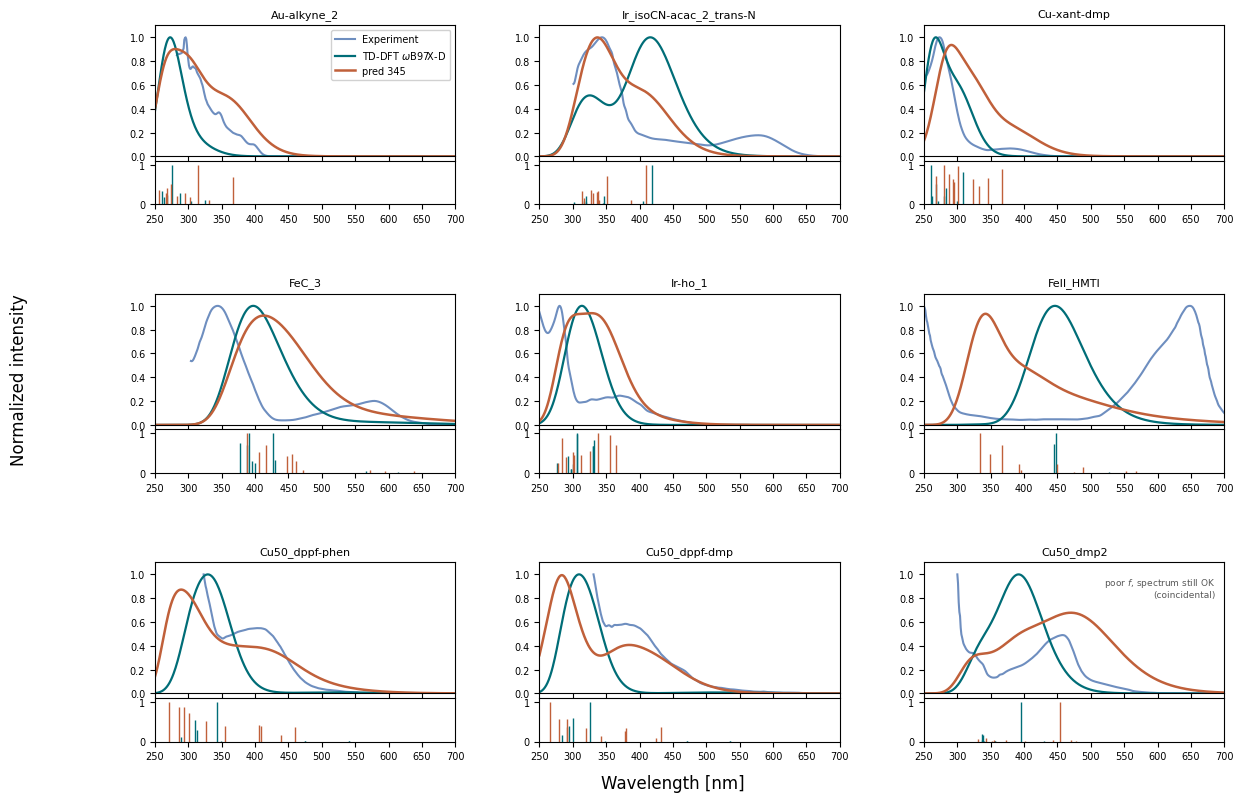

In [23]:
import re
from matplotlib.gridspec import GridSpec
HC = 1239.8419
GRID = np.arange(250, 701, 1.0)
SIGMA = 0.25


# --- Selection: (tag, stem) ---

SELECTION = [
    ('good',      'Au-alkyne_2'),
    ('good',      'Ir_isoCN-acac_2_trans-N'),
    ('good',      'Cu-xant-dmp'),
    ('follows',   'FeC_3'),
    ('follows',   'Ir-ho_1'),
    ('large err', 'FeII_HMTI'),
    ('Cu+Fe',     'Cu50_dppf-phen'),
    ('Cu+Fe',     'Cu50_dppf-dmp'),
    ('screening', 'Cu50_dmp2'),        
]
NCOLS = 3
NOTE = {'screening': 'poor $f$, spectrum still OK\n(coincidental)'}

def to_nm(E): return HC / np.asarray(E)

def nnf(fs): fs = np.asarray(fs, float); return fs / fs.max() if fs.max() > 0 else fs

def pred_states_mean(v, cls, nmax=10):
    recs = [r for r in (v['predictions'].get(cls) or {}).values() if r.get('energy_eV') and r.get('f')]
    if not recs: return None, None
    n = min(len(r['energy_eV']) for r in recs)
    E = np.mean([np.array(r['energy_eV'][:n]) for r in recs], axis=0)
    f = np.mean([np.array(r['f'][:n]) for r in recs], axis=0)
    return E[:nmax], f[:nmax]

def _norm(s): return re.sub(r'[^a-z0-9]', '', s.lower())
stem2file = {v['stem']: fn for fn, v in data.items()}
norm2file = {_norm(k): fn for k, fn in stem2file.items()}
def resolve(stem):
    if stem in stem2file: return stem2file[stem]
    n = _norm(stem)
    if n in norm2file: return norm2file[n]
    hits = [fn for k, fn in stem2file.items() if n in _norm(k)]
    return hits[0] if hits else None

def draw_cell(axT, axB, v, title, note=None):
    if v['experiment']: axT.plot(GRID, expt_curve(v), **STYLE['experiment'])
    if v['tddft']:
        ev = np.array(v['tddft']['energy_eV']); f = np.array(v['tddft']['f'])
        axT.plot(GRID, nn(broaden(ev[:TDDFT_NSTATES], f[:TDDFT_NSTATES])), **STYLE['tddft'])
    m = pred_spec_mean(v, '345')
    if m is not None: axT.plot(GRID, m, **STYLE['345'])
    axT.set_xlim(250, 700); axT.set_ylim(0, 1.1)
    axT.tick_params(labelsize=7, labelbottom=False); axT.set_title(title, fontsize=8)
    if note:
        axT.text(0.97, 0.90, note, transform=axT.transAxes, ha='right', va='top',
                 fontsize=6.5, color='0.35')
    if v['tddft']:
        ev = np.array(v['tddft']['energy_eV'])[:TDDFT_NSTATES]; f = np.array(v['tddft']['f'])[:TDDFT_NSTATES]
        axB.vlines(to_nm(ev), 0, nnf(f), color=STYLE['tddft']['color'], lw=1)
    Ep, fp = pred_states_mean(v, '345')
    if Ep is not None: axB.vlines(to_nm(Ep), 0, nnf(fp), color=STYLE['345']['color'], lw=1)
    axB.set_xlim(250, 700); axB.set_ylim(0, 1.1); axB.tick_params(labelsize=7)

items = []
for tag, stem in SELECTION:
    fn = resolve(stem)
    if fn is None: print(f'{tag}: not found "{stem}"'); continue
    items.append((tag, stem, fn))

N = len(items); nrows = int(np.ceil(N/NCOLS))
fig = plt.figure(figsize=(4.6*NCOLS, 3.1*nrows))
outer = GridSpec(nrows, NCOLS, figure=fig, hspace=0.5, wspace=0.28)
for k, (tag, stem, fn) in enumerate(items):
    r, c = divmod(k, NCOLS)
    inner = outer[r, c].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)
    axT = fig.add_subplot(inner[0]); axB = fig.add_subplot(inner[1], sharex=axT)
    draw_cell(axT, axB, data[fn], f'{stem}', note=NOTE.get(tag))
    if k == 0: axT.legend(fontsize=7, loc='upper right', framealpha=0.9)

fig.supylabel('Normalized intensity', fontsize=12)
fig.text(0.5, 0.06, 'Wavelength [nm]', ha='center', fontsize=12)
#fig.savefig('fig_main_spectra.eps', bbox_inches='tight')
plt.show()


## Spectral metrics


In [24]:
# Systematic correction: wavelength scaling alpha
# (Fehér and Stirling protocol, Eq. 1: energy enters as alpha^-1 * E)

import numpy as np
from scipy.stats import wasserstein_distance

X, SIGMA, TAU = np.linspace(0, 12, 5000), 0.25, 1e-8
HC = 1239.8419
NST = 10
TD_VARIANTS = {'TD-DFT_10': 10, 'TD-DFT_30': 30, 'TD-DFT_full': None}
ALPHA_FEHER = 1.13                     # Feher & Stirling, Tab. 1, wB97X-D
WINDOWS = {'measured': None,
           'photoactive 350-650 nm': (HC / 650.0, HC / 350.0)}
FIT_WINDOW = 'measured'                # on which window we fit alpha
FIT_ON = 'SRMSE'                       # fitting criterion (analog of Fehér's MSE)
MIN_PTS = 5
METRIC_NAMES = ['W', 'SID', 'SRMSE']

TEX = {'TD-DFT_10': r'TD-DFT$_{10}$', 'TD-DFT_30': r'TD-DFT$_{30}$',
       'TD-DFT_full': r'TD-DFT$_{\mathrm{full}}$',
       '345': r'$345$-trained', '3d': r'$3d$-trained'}

def clean_ef(rec, nmax=None):
    E = np.asarray(rec['energy_eV'], float); f = np.asarray(rec['f'], float)
    n = min(len(E), len(f)); E, f = E[:n], f[:n]
    m = np.isfinite(E) & np.isfinite(f)
    E, f = E[m], np.clip(f[m], 0.0, None)
    o = np.argsort(E); E, f = E[o], f[o]
    return (E[:nmax], f[:nmax]) if nmax else (E, f)

def broaden(E, f, alpha=1.0):
    """alpha scales the wavelength, i.e., energy enters as E/alpha."""
    s = np.zeros_like(X)
    if E.size == 0:
        return s
    Es = E / alpha
    for Ei, fi in zip(Es, f):
        s += fi * np.exp(-0.5 * ((X - Ei) / SIGMA) ** 2)
    return s

def exp_spec(v):
    e = v.get('experiment')
    if not e:
        return None
    lam = np.asarray(e['wavelength_nm'], float)
    it = np.asarray(e['intensity'], float)
    ok = np.isfinite(lam) & np.isfinite(it) & (lam > 0)
    if ok.sum() < MIN_PTS:
        return None
    E = HC / lam[ok]; it = np.clip(it[ok], 0.0, None)
    o = np.argsort(E); E, it = E[o], it[o]
    y = np.full_like(X, np.nan)
    m = (X >= E.min()) & (X <= E.max())
    if m.any():
        y[m] = np.interp(X[m], E, it)
    return y

def metrics(a, b, win):
    m = np.isfinite(a) & np.isfinite(b)
    if win is not None:
        m &= (X >= win[0]) & (X <= win[1])
    if m.sum() < MIN_PTS:
        return None
    x = X[m]
    P = np.maximum(a[m], TAU); P /= P.sum()
    Q = np.maximum(b[m], TAU); Q /= Q.sum()
    return (wasserstein_distance(x, x, P, Q),
            float(np.sum(P * np.log(P / Q) + Q * np.log(Q / P))),
            float(np.sqrt(np.mean((P - Q) ** 2))))

seeds = sorted({s for v in data.values() if v.get('predictions')
                for c in v['predictions'].values() for s in c})
usable = [v for v in data.values()
          if v.get('experiment') and v.get('tddft')
          and all(c in (v.get('predictions') or {}) for c in CLASSES)]
N = len(usable)
print(f"n = {N} complexes, seeds = {seeds}, sigma = {SIGMA} eV fixed\n")

EXPS = [exp_spec(v) for v in usable]
EF = []                                   # (E, f) once per complex per method
for v in usable:
    d = {k: clean_ef(v['tddft'], n) for k, n in TD_VARIANTS.items()}
    for cls in CLASSES:
        for s in seeds:
            r = (v.get('predictions') or {}).get(cls, {}).get(s)
            d[(cls, s)] = (clean_ef(r, NST) if r and r.get('energy_eV')
                           and r.get('f') else (np.array([]), np.array([])))
    EF.append(d)

METHODS = list(TD_VARIANTS) + CLASSES

def mean_metrics(method, alpha, win):
    """Mean (W, SID, SRMSE) over complexes. For models: mean over seeds,
       also returns the std across seeds."""
    if method in TD_VARIANTS:
        acc = []
        for ef, ex in zip(EF, EXPS):
            if ex is None: continue
            r = metrics(broaden(*ef[method], alpha), ex, win)
            if r: acc.append(r)
        if not acc: return None
        return np.mean(acc, axis=0), np.full(3, np.nan), len(acc)
    per_seed, ns = [], []
    for s in seeds:
        acc = []
        for ef, ex in zip(EF, EXPS):
            if ex is None: continue
            r = metrics(broaden(*ef[(method, s)], alpha), ex, win)
            if r: acc.append(r)
        if acc:
            per_seed.append(np.mean(acc, axis=0)); ns.append(len(acc))
    if not per_seed: return None
    return (np.mean(per_seed, axis=0), np.std(per_seed, axis=0), int(np.mean(ns)))


# ------------------------------------------------------------ alpha fitting
mi = METRIC_NAMES.index(FIT_ON)
win_fit = WINDOWS[FIT_WINDOW]
print("=" * 86)
print(f"FITTING alpha   (window: {FIT_WINDOW}, criterion: mean {FIT_ON})")
print("=" * 86)

ALPHA, PLATEAU = {}, {}
GRID = np.round(np.arange(0.80, 1.351, 0.02), 4)      # coarse
for meth in METHODS:
    curves = []
    for a in GRID:
        r = mean_metrics(meth, a, win_fit)
        curves.append(r[0] if r else np.full(3, np.inf))
    curves = np.asarray(curves)                        # (len(GRID), 3)

    # which alpha each metric would choose - from the same run
    a_by = {METRIC_NAMES[j]: float(GRID[int(np.nanargmin(curves[:, j]))])
            for j in range(3)}

    # refinement around the optimum of the FIT_ON criterion
    a0 = a_by[FIT_ON]
    fine = np.round(np.arange(a0 - 0.02, a0 + 0.0201, 0.005), 4)
    vals = []
    for a in fine:
        r = mean_metrics(meth, a, win_fit)
        vals.append(r[0][mi] if r else np.inf)
    best = float(fine[int(np.argmin(vals))])
    ALPHA[meth] = best

    # how shallow the optimum is: the alpha range where the criterion <= 1.01 * min
    col = curves[:, mi]
    ok = np.where(col <= 1.01 * np.nanmin(col))[0]
    PLATEAU[meth] = (float(GRID[ok[0]]), float(GRID[ok[-1]])) if len(ok) else (np.nan,)*2

    print(f"  {meth:<14} alpha = {best:.3f}   plateau(1%) "
          f"{PLATEAU[meth][0]:.2f}-{PLATEAU[meth][1]:.2f}   "
          f"per metric: " + ", ".join(f"{k}:{v:.2f}" for k, v in a_by.items()))

spread = {m: max(PLATEAU[m]) - min(PLATEAU[m]) for m in METHODS}
if any(v > 0.06 for v in spread.values()):
    print("\n  WARNING: plateau wider than 0.06 for: "
          + ", ".join(m for m, v in spread.items() if v > 0.06)
          + "  -> alpha poorly determined")

print(f"\n  value published by Fehér for wB97X-D: alpha = {ALPHA_FEHER}")

# ------------------------------------------------------------ scenarios
SCEN = {
    'uncorrected':              {m: 1.0 for m in METHODS},
    f'Feher alpha={ALPHA_FEHER} (TD only)':
        {**{m: ALPHA_FEHER for m in TD_VARIANTS}, **{c: 1.0 for c in CLASSES}},
    'each fitted':              dict(ALPHA),
}

RES = {}
for wname, win in WINDOWS.items():
    for sname, amap in SCEN.items():
        RES[(wname, sname)] = {m: mean_metrics(m, amap[m], win) for m in METHODS}

for wname in WINDOWS:
    print("\n" + "=" * 86)
    print(f"WINDOW: {wname}")
    print("=" * 86)
    for sname in SCEN:
        print(f"\n  --- {sname} ---")
        print(f"  {'method':<14}{'alpha':>7}{'n':>5}{'Wasserstein':>20}"
              f"{'SID':>20}{'SRMSE x1e-4':>20}")
        for m in METHODS:
            r = RES[(wname, sname)][m]
            if r is None: continue
            mu, sd, n = r
            def c(j, sc=1.0):
                return (f"{mu[j]*sc:.3f} ± {sd[j]*sc:.3f}" if np.isfinite(sd[j])
                        else f"{mu[j]*sc:.3f}")
            print(f"  {m:<14}{SCEN[sname][m]:>7.3f}{n:>5}{c(0):>20}{c(1):>20}"
                  f"{c(2, 1e4):>20}")

n = 127 complexes, seeds = ['1234', '2137', '42'], sigma = 0.25 eV fixed

FITTING alpha   (window: measured, criterion: mean SRMSE)
  TD-DFT_10      alpha = 1.155   plateau(1%) 1.14-1.16   per metric: W:0.88, SID:0.96, SRMSE:1.16
  TD-DFT_30      alpha = 1.145   plateau(1%) 1.14-1.14   per metric: W:1.08, SID:1.10, SRMSE:1.14
  TD-DFT_full    alpha = 1.145   plateau(1%) 1.14-1.16   per metric: W:1.12, SID:1.12, SRMSE:1.14
  3d             alpha = 1.040   plateau(1%) 1.02-1.06   per metric: W:0.82, SID:0.88, SRMSE:1.04
  345            alpha = 1.070   plateau(1%) 1.04-1.10   per metric: W:0.84, SID:0.90, SRMSE:1.08


  value published by Fehér for wB97X-D: alpha = 1.13

WINDOW: measured

  --- uncorrected ---
  method          alpha    n         Wasserstein                 SID         SRMSE x1e-4
  TD-DFT_10       1.000  127               0.373               2.556              15.074
  TD-DFT_30       1.000  127               0.227               1.133              12.931
  TD-DFT_full  

## CPU-time on TD-DFT

In [10]:
import os
os.chdir('../tmphotocat')
os.getcwd()

import re

stems = list(data.keys())
logs = [re.sub(r'PBE-D3_def2SVP_coords[_-]?\d+\.xyz$', 'wB97XD_def2SVP.log', s) for s in stems]
logs.append('CuBCz_wB97XD_def2SVP.log')

l = []
for f in logs[:]:
    if 'wB97XD' in f:
        with open(f, 'r') as f:
            lines = f.readlines()

        print(f"File: {f.name}")
        print(lines[-4:-3])
        l.append(lines[-4:-3])

print(len(l))

File: Au-alkyne_2_wB97XD_def2SVP.log
[' Job cpu time:       0 days 14 hours 22 minutes 20.1 seconds.\n']
File: AuBCz_wB97XD_def2SVP.log
[' Job cpu time:       1 days 21 hours 27 minutes 13.8 seconds.\n']
File: Cu-phen_2_wB97XD_def2SVP.log
[' Job cpu time:       0 days 10 hours 57 minutes 41.7 seconds.\n']
File: Cu-xant-dmp_wB97XD_def2SVP.log
[' Job cpu time:       2 days  0 hours 26 minutes 10.4 seconds.\n']
File: Cu-xant-dppz_wB97XD_def2SVP.log
[' Job cpu time:       2 days  3 hours  5 minutes 24.0 seconds.\n']
File: Cu-xant-dpq_wB97XD_def2SVP.log
[' Job cpu time:       2 days  4 hours 26 minutes 19.1 seconds.\n']
File: Cu50_BINAP_batho_wB97XD_def2SVP.log
[' Job cpu time:       2 days 15 hours 28 minutes 31.4 seconds.\n']
File: Cu50_BINAP_dmbp_wB97XD_def2SVP.log
[' Job cpu time:       2 days  1 hours 48 minutes 25.2 seconds.\n']
File: Cu50_BINAP_dmp_wB97XD_def2SVP.log
[' Job cpu time:       2 days  7 hours 22 minutes 15.4 seconds.\n']
File: Cu50_BINAP_dq_wB97XD_def2SVP.log
[' Job cpu 

In [ ]:
import re, numpy as np

PAT = re.compile(r"(\d+)\s+days?\s+(\d+)\s+hours?\s+(\d+)\s+minutes?\s+([\d.]+)\s+seconds")

def to_hours(s):
    m = PAT.search(s)
    if not m: return None
    d, h, mi, sec = map(float, m.groups())
    return d * 24 + h + mi / 60 + sec / 3600

per_file, skipped = [], 0
for sub in l:                      
    vals = [to_hours(s) for s in (sub if isinstance(sub, list) else [sub])]
    vals = [v for v in vals if v is not None]
    if vals: per_file.append(sum(vals))
    else:    skipped += 1

h = np.array(per_file)
print(f"files   : {len(h)}   (skipped: {skipped})")
print(f"avg    : {h.mean():7.2f} CPU-h")
print(f"median    : {np.median(h):7.2f} CPU-h")
print(f"IQR        : {np.percentile(h,25):.2f} – {np.percentile(h,75):.2f} CPU-h")
print(f"min – max  : {h.min():.2f} – {h.max():.2f} CPU-h")
print(f"sum     : {h.sum():7.1f} CPU-h")

files   : 131   (skipped: 0)
avg    :   34.85 CPU-h
median    :   30.99 CPU-h
IQR        : 17.02 – 49.75 CPU-h
min – max  : 7.49 – 112.33 CPU-h
sum     :  4565.4 CPU-h
